In [2]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

stock_list=["AAPL", "MSFT", "SAP.DE","NVDA","TSLA",
            "SIE.DE","ALV.DE","JPM","GS", "BAYN.DE"]

data=yf.download(stock_list,start="2025-11-01" ,interval="1d")

# data['Close'].head(10)
# data.info()
# data['Close'].isna().sum()

data['Close']=np.log(data['Close']/data['Close'].shift(1))
data=data.dropna()

print(data["Close"].head())

# data["Close"]=data["Close"].ffill()
# print(data["Close"])

[*********************100%***********************]  10 of 10 completed

Ticker          AAPL    ALV.DE   BAYN.DE        GS       JPM      MSFT  \
Date                                                                     
2025-11-04  0.003673  0.002264  0.010709  0.006737 -0.000323 -0.005236   
2025-11-05  0.000370  0.007041 -0.012411  0.002854  0.007827 -0.014039   
2025-11-06 -0.001371 -0.008455  0.003212 -0.006972  0.005567 -0.020035   
2025-11-07 -0.004830 -0.003686 -0.017312 -0.001576  0.002517 -0.000563   
2025-11-10  0.004538  0.013544  0.016935  0.013716  0.008493  0.018309   

Ticker          NVDA    SAP.DE    SIE.DE      TSLA  
Date                                                
2025-11-04 -0.040393 -0.012311 -0.012210 -0.052849  
2025-11-05 -0.017670  0.008370  0.003271  0.039306  
2025-11-06 -0.037209 -0.044861 -0.013975 -0.035599  
2025-11-07  0.000372 -0.010609 -0.017958 -0.037449  
2025-11-10  0.056317  0.002778  0.034786  0.035923  


In [27]:
excel_aktien=data.dropna()

excel_aktien[["Close"]].to_excel("Aktienkurse_log_returns3.xlsx", index=True)

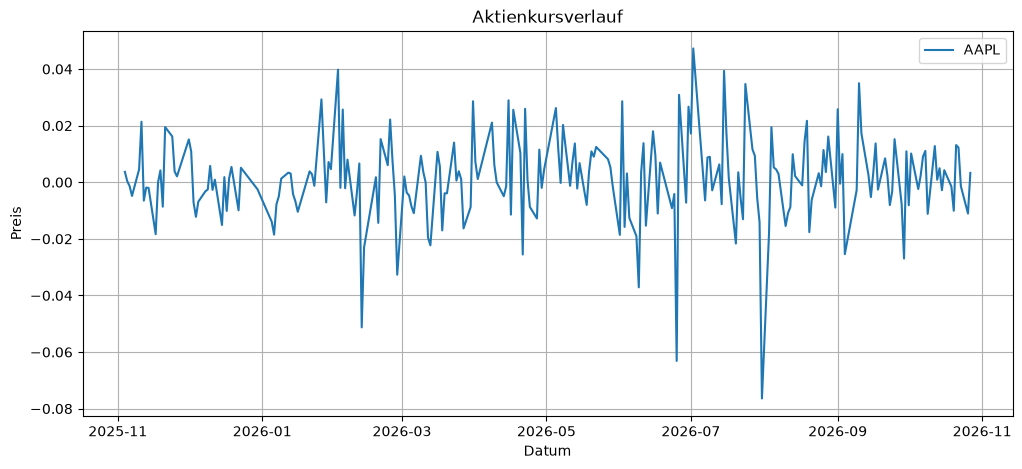

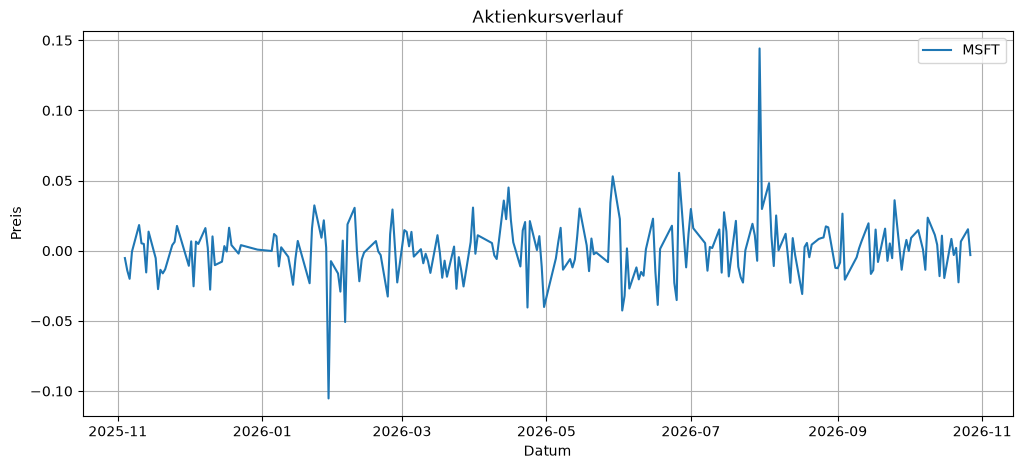

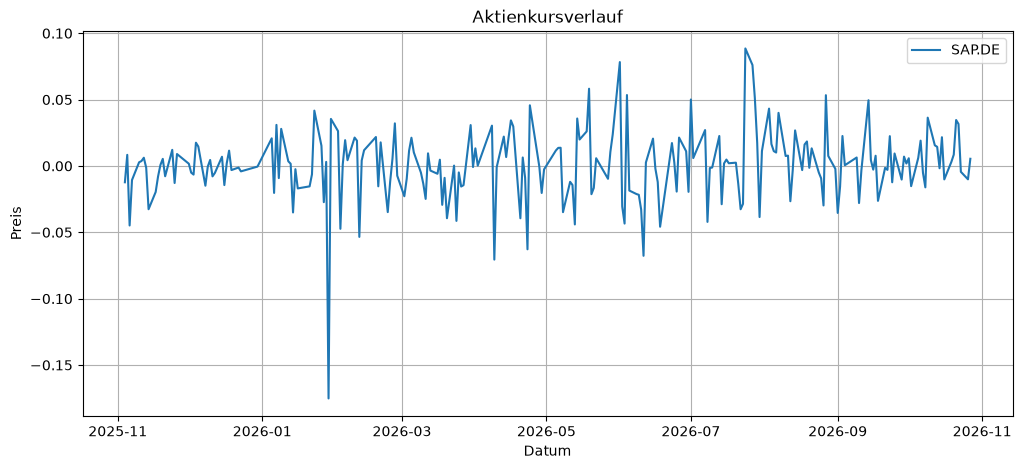

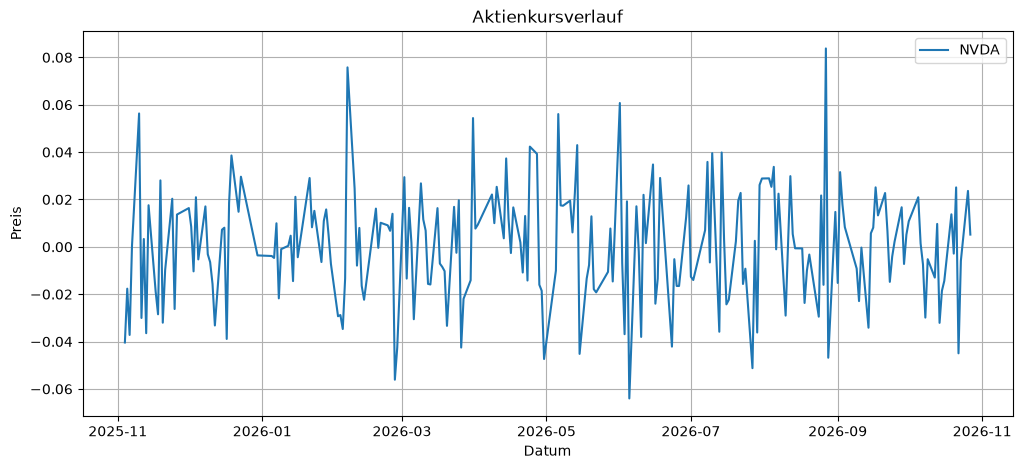

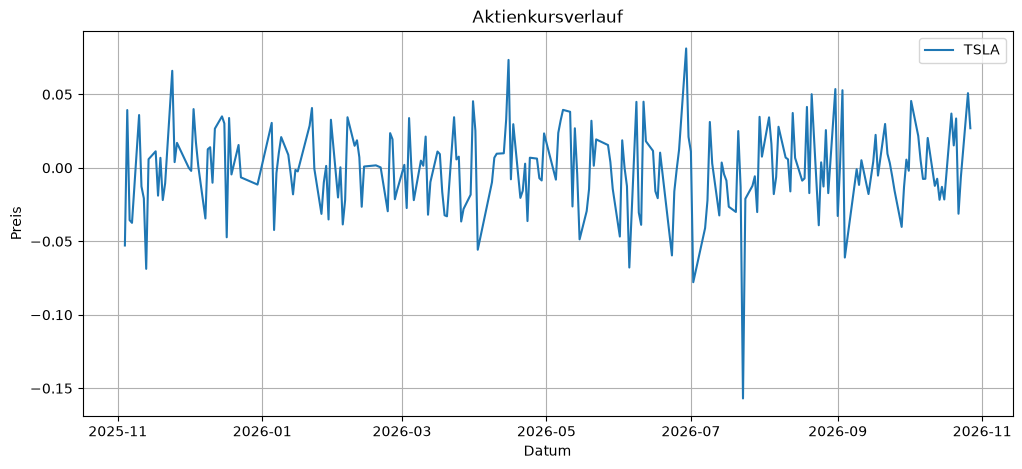

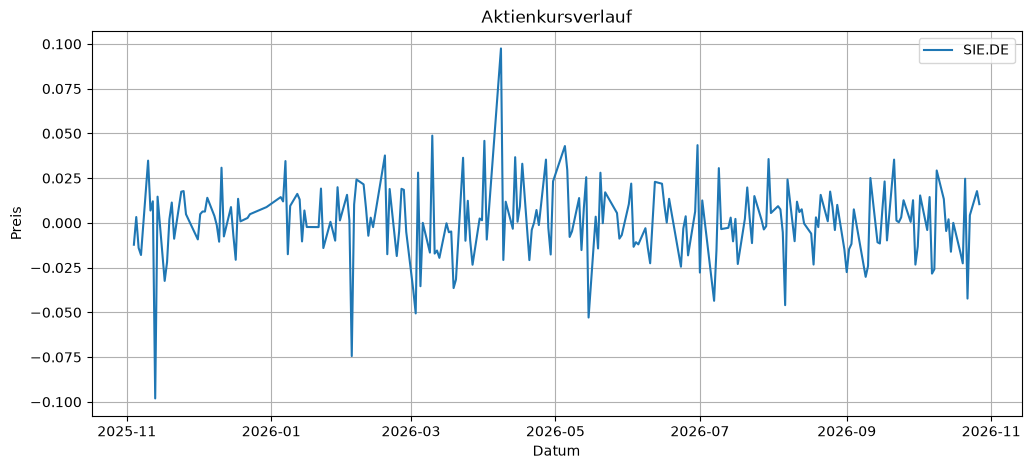

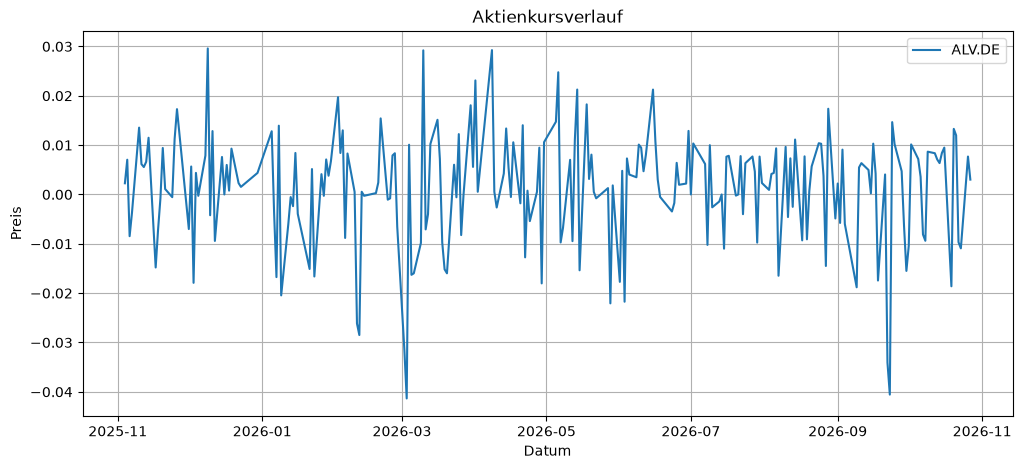

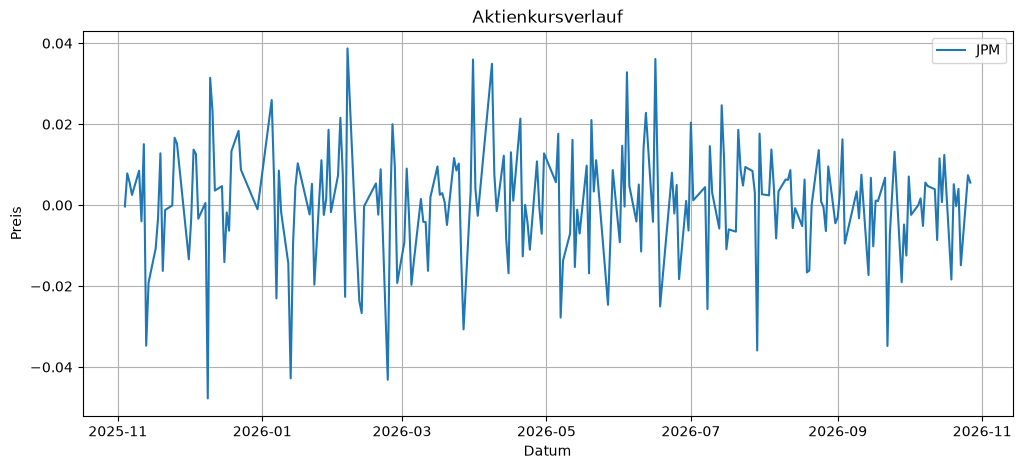

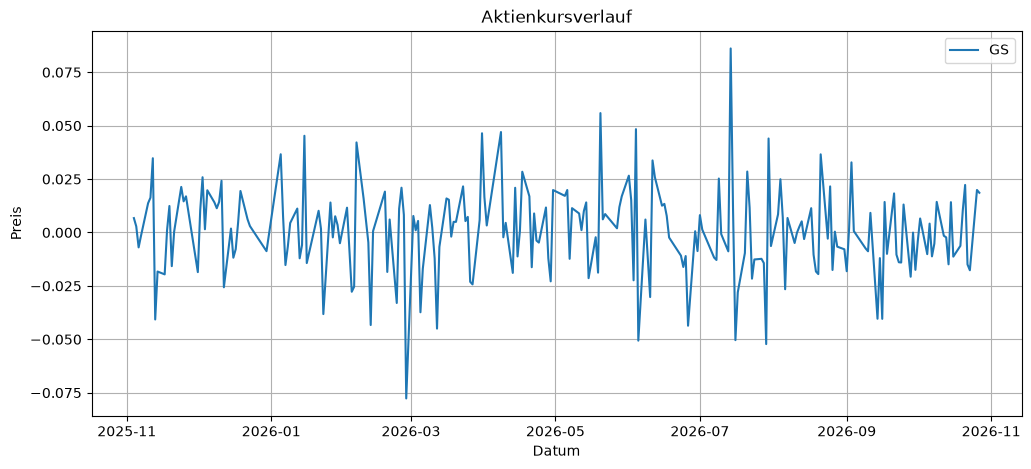

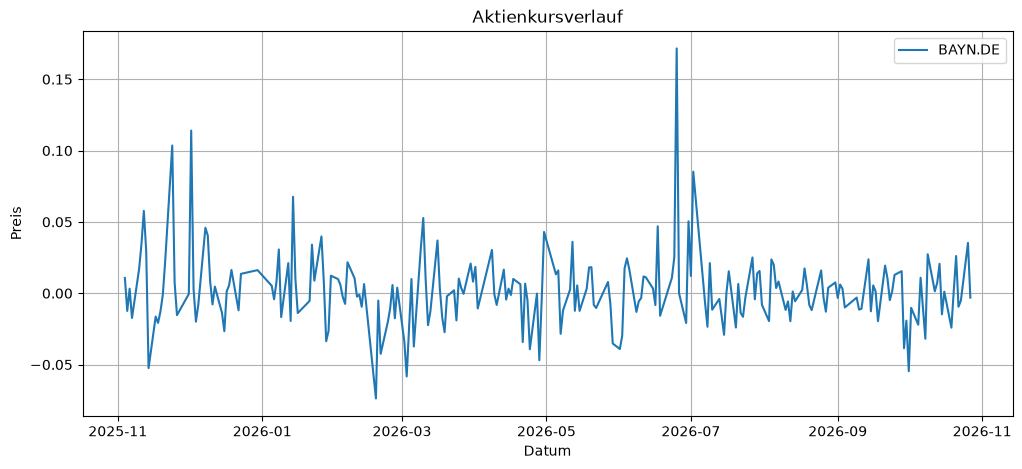

In [28]:
for stock in stock_list:
    plt.figure(figsize=(12,5))
    plt.plot(data["Close"][stock],label=stock)
    plt.title("Aktienkursverlauf")
    plt.xlabel("Datum")
    plt.ylabel("Preis")
    plt.grid(True)
    plt.legend()
    plt.show()
    

## Forecasting with Chronos-2



In [29]:
import os
# Use only 1 GPU if available
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from chronos import BaseChronosPipeline, Chronos2Pipeline

# Load the Chronos-2 pipeline
# GPU recommended for faster inference, but CPU is also supported using device_map="cpu"
pipeline: Chronos2Pipeline = BaseChronosPipeline.from_pretrained("amazon/chronos-2", device_map="cpu")

/Users/n1ght/Projekte/chronos-forecasting/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1027 15:41:12.954000 69194 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 170/170 [00:00<00:00, 6779.41it/s]


In [42]:

## Transforming data into the shape of the prediction model

data=yf.Ticker("AAPL").history(start="2025-11-01" ,interval="1d")


data['Close']=np.log(data['Close']/data['Close'].shift(1))

data=data.dropna()

data_transformed=(data[["Close"]].reset_index().rename(columns={"Date": "timestamp"}))

data_transformed["timestamp"]=(pd.to_datetime(data_transformed["timestamp"]).dt.tz_localize(None))

data_transformed["id"]="AAPL"


data_transformed=(
    data_transformed[["id","timestamp","Close"]]
    .dropna(subset=["timestamp","Close"])
    .sort_values(["id","timestamp"])
    .reset_index(drop=True)
)


print("Input data:",data_transformed.shape)
print(data_transformed.head(10))

Input data: (246, 3)
     id  timestamp     Close
0  AAPL 2025-11-04  0.003673
1  AAPL 2025-11-05  0.000370
2  AAPL 2025-11-06 -0.001371
3  AAPL 2025-11-07 -0.004830
4  AAPL 2025-11-10  0.004538
5  AAPL 2025-11-11  0.021371
6  AAPL 2025-11-12 -0.006488
7  AAPL 2025-11-13 -0.001903
8  AAPL 2025-11-14 -0.001980
9  AAPL 2025-11-17 -0.018338


In [43]:
# Prediciton of 15 days of AAPL


pred_df = pipeline.predict_df(data_transformed, prediction_length=15, quantile_levels=[0.1, 0.5, 0.9],timestamp_column='timestamp', id_column='id', target='Close',freq="B")

print("Output dataframe shape:", pred_df.shape)
display(pred_df.head(15))


Output dataframe shape: (15, 7)


,id,timestamp,target_name,predictions,0.1,0.5,0.9
0,AAPL,2026-10-28,Close,0.000506,-0.018258,0.000506,0.018327
1,AAPL,2026-10-29,Close,0.000463,-0.017828,0.000463,0.017998
2,AAPL,2026-10-30,Close,0.000586,-0.016677,0.000586,0.017776
3,AAPL,2026-11-02,Close,0.000653,-0.015842,0.000653,0.016920
4,AAPL,2026-11-03,Close,0.000577,-0.016036,0.000577,0.016851
5,AAPL,2026-11-04,Close,0.000594,-0.015887,0.000594,0.016606
6,AAPL,2026-11-05,Close,0.000713,-0.015562,0.000713,0.016844
7,AAPL,2026-11-06,Close,0.000652,-0.016487,0.000652,0.017578
8,AAPL,2026-11-09,Close,0.000589,-0.018658,0.000589,0.019165
9,AAPL,2026-11-10,Close,0.000548,-0.020137,0.000548,0.020984


In [44]:
# Visualization helper function
def plot_forecast(
    context_df: pd.DataFrame,
    pred_df: pd.DataFrame,
    test_df: pd.DataFrame,
    target_column: str,
    timeseries_id: str,
    id_column: str = "id",
    timestamp_column: str = "timestamp",
    history_length: int = 256,
    title_suffix: str = "",
):
    ts_context = context_df.query(f"{id_column} == @timeseries_id").set_index(timestamp_column)[target_column]
    ts_pred = pred_df.query(f"{id_column} == @timeseries_id and target_name == @target_column").set_index(
        timestamp_column
    )[["0.1", "predictions", "0.9"]]
    ts_ground_truth = test_df.query(f"{id_column} == @timeseries_id").set_index(timestamp_column)[target_column]

    last_date = ts_context.index.max()
    start_idx = max(0, len(ts_context) - history_length)
    plot_cutoff = ts_context.index[start_idx]
    ts_context = ts_context[ts_context.index >= plot_cutoff]
    ts_pred = ts_pred[ts_pred.index >= plot_cutoff]
    ts_ground_truth = ts_ground_truth[ts_ground_truth.index >= plot_cutoff]

    fig = plt.figure(figsize=(12, 3))
    ax = fig.gca()
    ts_context.plot(ax=ax, label=f"historical {target_column}", color="xkcd:azure")
    ts_ground_truth.plot(ax=ax, label=f"future {target_column} (ground truth)", color="xkcd:grass green")
    ts_pred["predictions"].plot(ax=ax, label="forecast", color="xkcd:violet")
    ax.fill_between(
        ts_pred.index,
        ts_pred["0.1"],
        ts_pred["0.9"],
        alpha=0.7,
        label="prediction interval",
        color="xkcd:light lavender",
    )
    ax.axvline(x=last_date, color="black", linestyle="--", alpha=0.5)
    ax.legend(loc="upper left")
    ax.set_title(f"{target_column} forecast for {timeseries_id} {title_suffix}")
    fig.show()

/var/folders/jp/v300n9jx4fz3_pd5kjcmtnr40000gn/T/ipykernel_69194/2710048652.py:42: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


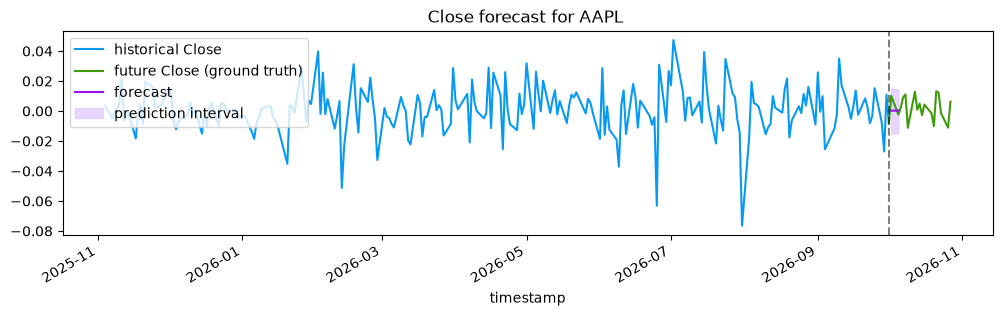

In [52]:
context_day="2026-10-01"

context_data=data_transformed[data_transformed["timestamp"]<=context_day].copy()

test_data=data_transformed[data_transformed["timestamp"]>=context_day].copy()

pred_df = pipeline.predict_df(context_data, prediction_length=2, quantile_levels=[0.1, 0.5, 0.9],timestamp_column='timestamp', id_column='id', target='Close',freq="B")

plot_forecast(
    context_df=context_data,
    pred_df=pred_df,
    test_df=test_data,
    target_column="Close",
    timeseries_id="AAPL",  
    id_column="id",
)



